# Red Neuronal Simple (una capa oculta)

Este ejemplo muestra la implementación de una red neuronal simple con la siguiente arquitectura:
- Una capa de entrada
- Una capa oculta
- Una capa de salida

La función de activación en la capa oculta será "tanh" y en la capa de salida será una función sigmoidea.

In [1]:
# Se requiere numpy y matplotlib
import numpy as np
import matplotlib.pyplot as plt

# Red neuronal
from simple_nn import SimpleNeuralNetwork

# Funciones de ayuda para cargar datos y gráficos
from funciones_ayuda import generar_datos_petalos, plot_decision_boundary

## 1. Lectura de los datos ##

Los datos corresponden a dos clases distribuidas en forma de pétalos.

Tamaño de X: (2, 400)
Tamaño de Y: (1, 400)
Número de instancias de entrenamiento: 400


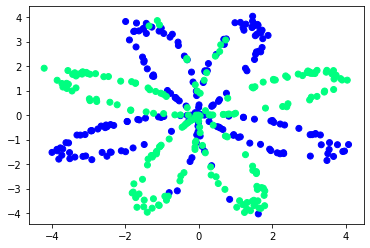

In [2]:
# cargar los datos
X, Y = generar_datos_petalos()

# Mostrar tamaños
n = X.shape[1]   # Número de instancias
print ('Tamaño de X:', str(X.shape))
print ('Tamaño de Y:', str(Y.shape))
print ('Número de instancias de entrenamiento:', str(n))

# Visualizar los datos
plt.scatter(X[0, :], X[1, :], c=Y.flatten(), cmap='winter');

## 2. Red Neuronal

### Entrenamiento

Se utilizará una red neuronal con 5 neuronas en la capa oculta y una neurona en la capa de salida. 
Por defecto el modelo asume solamente 2 capas: la capa oculta tiene función de activación tanh, y la capa de salida tiene función de activación sigmoidea

In [3]:
# Creación del modelo
nneuronas = 5
modelo = SimpleNeuralNetwork(nhidden=nneuronas, num_iter=10000, learning_rate=0.5, verbose=True)

# Entrenamiento de la red neuronal
modelo.fit(X, Y)

Costo luego de la iteración 0: 0.6933
Costo luego de la iteración 1000: 0.3019
Costo luego de la iteración 2000: 0.2871
Costo luego de la iteración 3000: 0.2794
Costo luego de la iteración 4000: 0.2739
Costo luego de la iteración 5000: 0.2698
Costo luego de la iteración 6000: 0.2666
Costo luego de la iteración 7000: 0.2639
Costo luego de la iteración 8000: 0.2616
Costo luego de la iteración 9000: 0.2595


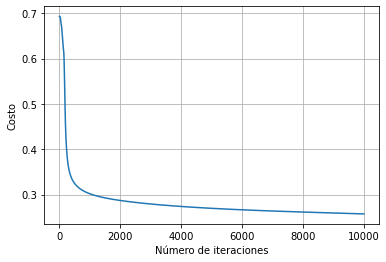

In [4]:
# Graficar la función de costo
plt.plot(modelo.costo)
plt.grid()
plt.xlabel("Número de iteraciones"); plt.ylabel("Costo");

### Predicciones

Exactitud con 5 neuronas en capa oculta: 91.0 %


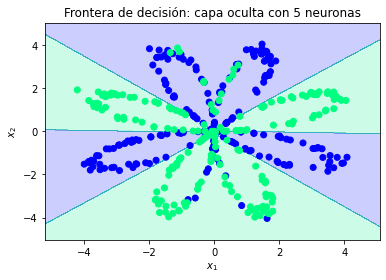

In [5]:
# Predicciones para X
Ypred = modelo.predict(X)

# Exactitud en el conjunto de entrenamiento
exactitud = (np.dot(Y, Ypred.T) + np.dot(1-Y, 1-Ypred.T))/float(Y.size)*100
print("Exactitud con {} neuronas en capa oculta: {} %".format(nneuronas, exactitud.item() ))

# Gráfico de la frontera de decisión
plot_decision_boundary(modelo, X, Y)
plt.title("Frontera de decisión: capa oculta con {} neuronas".format(nneuronas));

### Variación de número de neuronas en la capa oculta

Exactitud con 1 neuronas en capa oculta: 67.25 %
Exactitud con 2 neuronas en capa oculta: 67.0 %
Exactitud con 3 neuronas en capa oculta: 90.75 %
Exactitud con 4 neuronas en capa oculta: 90.5 %
Exactitud con 5 neuronas en capa oculta: 91.0 %
Exactitud con 20 neuronas en capa oculta: 91.0 %
Exactitud con 50 neuronas en capa oculta: 90.75 %


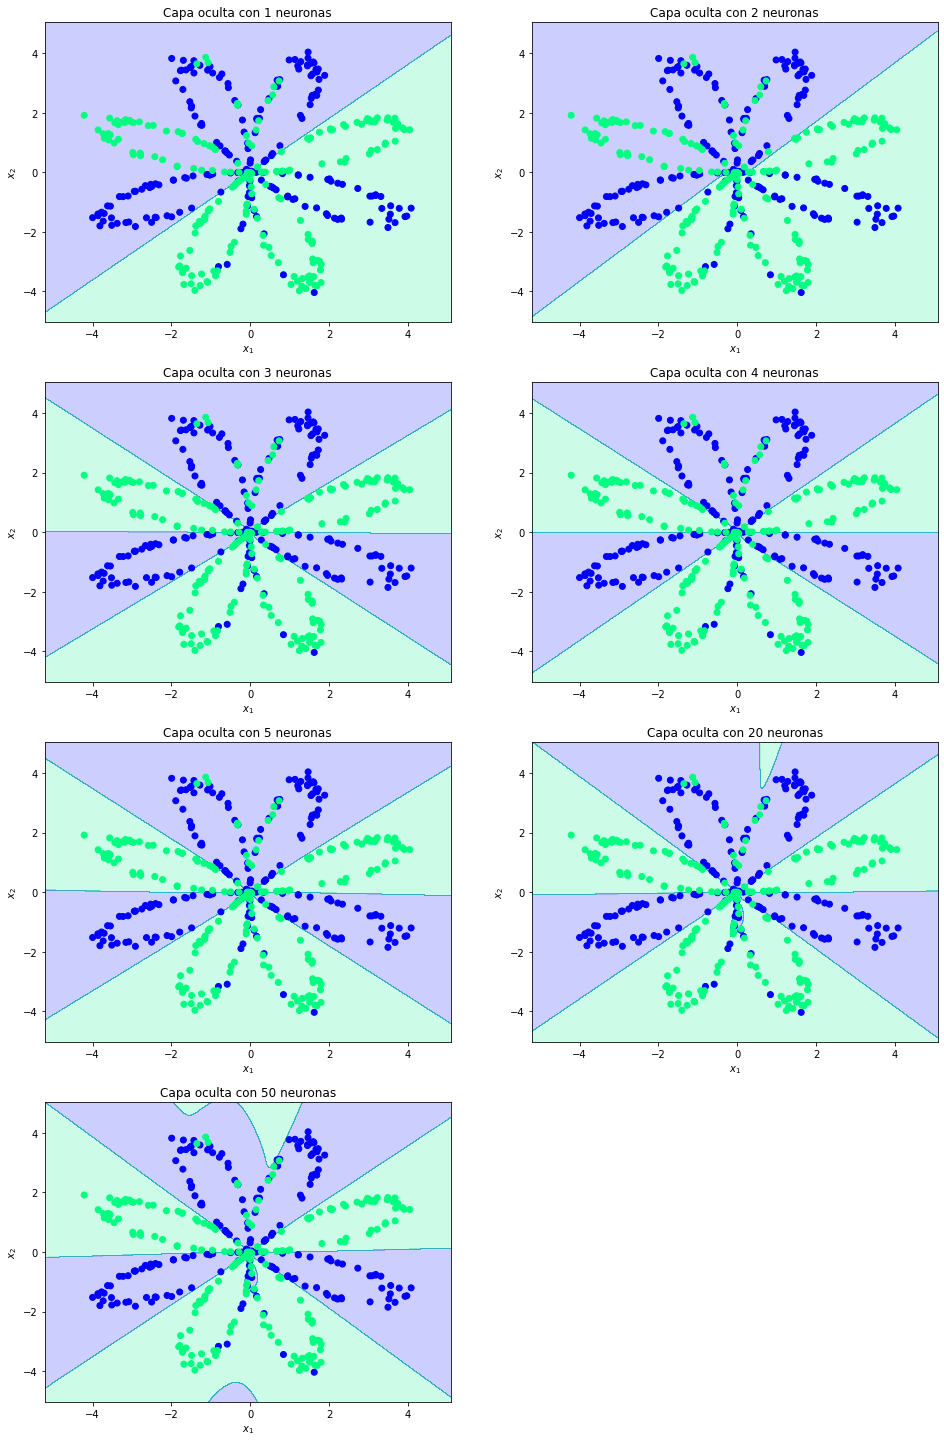

In [6]:
plt.figure(figsize=(16, 32))
num_neuronas = [1, 2, 3, 4, 5, 20, 50]

for i, nh in enumerate(num_neuronas):
    plt.subplot(5, 2, i+1)
    plt.title('Capa oculta con {} neuronas'.format(nh))
    
    # Modelos con diferentes números de neuronas
    modelo = SimpleNeuralNetwork(nhidden=nh, num_iter=5000, learning_rate=1.0)
    modelo.fit(X, Y)
    
    # Gráfico de frontera de decisión
    plot_decision_boundary(modelo, X, Y)
    
    # Cálculo de la exactitud
    Ypred = modelo.predict(X)
    exactitud = (np.dot(Y, Ypred.T) + np.dot(1-Y, 1-Ypred.T))/float(Y.size)*100
    print("Exactitud con {} neuronas en capa oculta: {} %".format(nh, exactitud.item() ))